<a href="https://colab.research.google.com/github/baovrnguyen/Credit-Default-Risk-Manual-Review/blob/main/Credit_Default_Risk_Manual_Review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install ucimlrepo pandas numpy scikit-learn

In [ ]:
# To save figures
import os

figure_dir = "figures"
os.makedirs(figure_dir, exist_ok=True)

Mounted at /content/drive


In [ ]:
# Setup + Reproducibility

import numpy as np
import pandas as pd

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 5622

# Bank review up to 1,000 of 30,000 accounts
REVIEW_RATE = 1000 / 30000

# Load the data
credit = fetch_ucirepo(id=350)

X = credit.data.features.copy()
y = credit.data.targets.squeeze().astype(int)


# Give the predictors their meaningful names
feature_names = [
    "LIMIT_BAL",
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "AGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6",]

assert X.shape[1] == len(feature_names)

X.columns = feature_names

# Apply cleaning => undocumented EDUCATION codes 0, 5, and 6 -> 4 = "other"
X["EDUCATION"] = X["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4,})


# PAY values -2 and 0 remain separate categories.
pay_cols = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",]

# Locked 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED,)

print("Train/Test Split:")
print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("Train default rate:", round(y_train.mean(), 3))
print("Test default rate:", round(y_test.mean(), 3))

# Manual review capacity
test_review_budget = int(round(REVIEW_RATE * len(X_test)))

assert test_review_budget == 200

print("Review Capacity:")
print("Review rate:", round(REVIEW_RATE, 4))
print("Test review budget:", test_review_budget)

# Define categorical and numeric predictors
categorical_cols = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",]

numeric_cols = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6",]

# Make sure all 23 predictors are accounted for exactly once
assert set(X.columns) == set(categorical_cols + numeric_cols)

assert len(categorical_cols) + len(numeric_cols) == X.shape[1]

# Define preprocessing
# Logistic regression preprocessing:
# - one-hot encode categorical predictors
# - standardize numeric predictors
logistic_preprocessor = ColumnTransformer([
    ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_cols,),
    ("num",StandardScaler(),numeric_cols,),])

# Tree-model preprocessing:
# - one-hot encode categorical predictors
# - leave numeric predictors unchanged
tree_preprocessor = ColumnTransformer([
    ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_cols,),
    ("num","passthrough",numeric_cols,),])

# Locked 5-fold cross-validation
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED,)

# Metric: Recall at review capacity
def recall_at_capacity(y_true,risk_score,review_rate=REVIEW_RATE,):
# Rank accounts from highest to lowest risk and review only the top review_rate fraction.
# Returns: proportion of all actual defaulters captured within the review pool

    y_true = np.asarray(y_true)
    risk_score = np.asarray(risk_score)

    k = max(1,int(round(review_rate * len(y_true))))

    # Rank highest risk first
    ranked_idx = np.argsort(risk_score)[::-1]

    # Accounts selected for manual review
    selected_idx = ranked_idx[:k]

    defaults_captured = y_true[selected_idx].sum()
    total_defaults = y_true.sum()

    recall = defaults_captured / total_defaults

    return recall

# Decision evaluation
def evaluate_at_capacity(y_true,risk_score,review_rate=REVIEW_RATE,):

    y_true = np.asarray(y_true)
    risk_score = np.asarray(risk_score)

    k = max(1,int(round(review_rate * len(y_true))))

    ranked_idx = np.argsort(risk_score)[::-1]
    selected_idx = ranked_idx[:k]

    captured = int(y_true[selected_idx].sum())

    total_defaults = int(y_true.sum())

    recall = captured / total_defaults

    return {"reviewed": k,
        "defaults_captured": captured,
        "total_defaults": total_defaults,
        "recall": recall,}

# Baseline: Rank customers by the most recent repayment delay PAY_0, with higher/worse values ranked first.
# Break ties using the most recent bill balance relative to the customer's credit limit.
def evaluate_baseline( X_eval,y_eval,review_rate=REVIEW_RATE,):

    temp = pd.DataFrame(index=X_eval.index)

    # Primary ranking variable
    temp["PAY_0"] = X_eval["PAY_0"]

    # Tie-breaker
    temp["recent_utilization"] = (X_eval["BILL_AMT1"]/ X_eval["LIMIT_BAL"])

    # Evaluation labels only
    temp["actual_default"] = np.asarray(y_eval)

    # Lexicographic ranking:
    # PAY_0 first, utilization second
    ranked = temp.sort_values(by=["PAY_0","recent_utilization",],
        ascending=[False,False,],)

    k = max(1,int(round(review_rate * len(ranked))))

    reviewed = ranked.iloc[:k]

    captured = int(reviewed["actual_default"].sum())

    total_defaults = int(temp["actual_default"].sum())

    recall = captured / total_defaults
    precision = captured / k

    return {"reviewed": k,
        "defaults_captured": captured,
        "total_defaults": total_defaults,
        "recall": recall,}

# Evaluate baseline on 5 CV folds
baseline_results = []

for fold, (_, val_idx) in enumerate(cv.split(X_train, y_train),start=1,):

    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    result = evaluate_baseline(X_val,y_val,)

    result["fold"] = fold

    baseline_results.append(result)


baseline_results = pd.DataFrame(baseline_results)

# Reorder columns for readability
baseline_results = baseline_results[[
        "fold",
        "reviewed",
        "defaults_captured",
        "total_defaults",
        "recall",]]

# Baseline CV performance
print("BASELINE 5-FOLD CV RESULTS:")

print(baseline_results.to_string(
        index=False,
        formatters={"recall": "{:.3f}".format,},))


mean_baseline_recall = (baseline_results["recall"].mean())

std_baseline_recall = (baseline_results["recall"].std())


print("\nMean baseline Recall:",round(mean_baseline_recall, 3))

print( "SD baseline Recall:",round(std_baseline_recall, 3))

# Each validation fold has about 4,800 customers.
# 3.33% of 4,800 = 160 accounts.
assert (baseline_results["reviewed"] == 160).all()



===== TRAIN / TEST SPLIT =====
Train: (24000, 23)
Test: (6000, 23)
Train default rate: 0.221
Test default rate: 0.221

===== REVIEW CAPACITY =====
Review rate: 0.0333
Test review budget: 200

===== BASELINE 5-FOLD CV RESULTS =====
 fold  reviewed  defaults_captured  total_defaults recall
    1       160                105            1061  0.099
    2       160                107            1062  0.101
    3       160                110            1062  0.104
    4       160                102            1062  0.096
    5       160                113            1062  0.106

Mean baseline Recall: 0.101
SD baseline Recall: 0.004


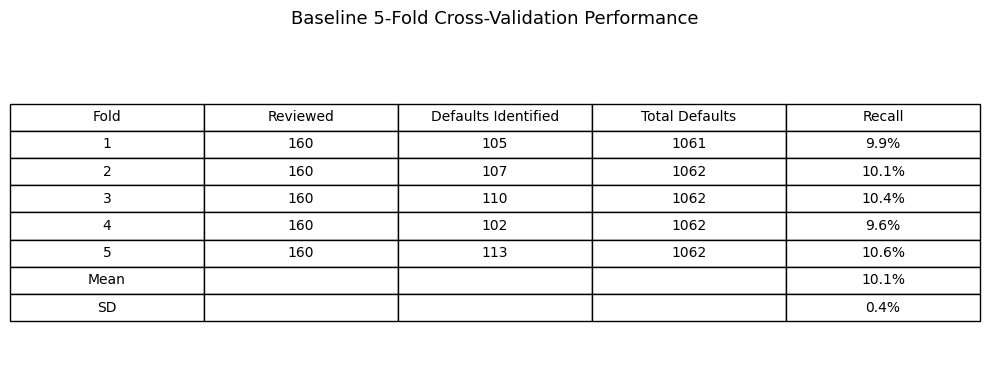

In [ ]:
# Baseline CV Results Table

import matplotlib.pyplot as plt
import pandas as pd


# Table from CV results
baseline_table = baseline_results.copy()

baseline_table["recall"] = baseline_table["recall"].map(
    lambda x: f"{x:.1%}")

baseline_table = baseline_table.rename(columns={
    "fold": "Fold",
    "reviewed": "Reviewed",
    "defaults_captured": "Defaults Identified",
    "total_defaults": "Total Defaults",
    "recall": "Recall",})


# Summary rows
mean_row = pd.DataFrame({
    "Fold": ["Mean"],
    "Reviewed": [""],
    "Defaults Identified": [""],
    "Total Defaults": [""],
    "Recall": [f"{baseline_results['recall'].mean():.1%}"],})

sd_row = pd.DataFrame({
    "Fold": ["SD"],
    "Reviewed": [""],
    "Defaults Identified": [""],
    "Total Defaults": [""],
    "Recall": [f"{baseline_results['recall'].std():.1%}"]})


baseline_table = pd.concat([baseline_table, mean_row, sd_row], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 4))

ax.axis("off")

table = ax.table(
    cellText=baseline_table.values,
    colLabels=baseline_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)

ax.set_title("Baseline 5-Fold Cross-Validation Performance", fontsize=13, pad=15)

plt.tight_layout()

plt.savefig(f"{figure_dir}/baseline_cv_table.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

C_values = [0.01, 0.1, 1, 10]
logistic_results = []

for C in C_values:
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):

        # Current CV split
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Fresh pipeline for this fold
        model = Pipeline([
            ("preprocess", ColumnTransformer([
                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
                ("num", StandardScaler(), numeric_cols),])),
            ("model", LogisticRegression(
                C=C, penalty="l2", max_iter=5000, random_state=SEED)),])

        # Fit only on this fold's training data
        model.fit(X_fold_train, y_fold_train)

        # Default-risk probabilities for validation accounts
        val_risk = model.predict_proba(X_fold_val)[:, 1]

        # Bank's headline metric
        result = evaluate_at_capacity(y_fold_val, val_risk)

        logistic_results.append({
            "C": C,
            "fold": fold,
            "reviewed": result["reviewed"],
            "defaults_captured": result["defaults_captured"],
            "total_defaults": result["total_defaults"],
            "recall": result["recall"], })

logistic_results = pd.DataFrame(logistic_results)

print(logistic_results.head())

assert (logistic_results["reviewed"] == 160).all()

logistic_summary = (logistic_results.groupby("C") .agg(mean_recall=("recall", "mean"),
    sd_recall=("recall", "std")).reset_index())

print(logistic_summary.to_string(
    index=False,
    formatters={
        "mean_recall": "{:.3f}".format,
        "sd_recall": "{:.3f}".format,}))

best_row = logistic_summary.loc[logistic_summary["mean_recall"].idxmax()]
best_C = best_row["C"]

print("\nBest C:", best_C)
print("Best CV Recall:", round(best_row["mean_recall"], 3))

print("\nBaseline mean Recall:", round(mean_baseline_recall, 3))
print("Logistic mean Recall:", round(best_row["mean_recall"], 3))
print("Improvement:", round(best_row["mean_recall"] - mean_baseline_recall, 3))

      C  fold  reviewed  defaults_captured  total_defaults    recall
0  0.01     1       160                118            1061  0.111216
1  0.01     2       160                125            1062  0.117702
2  0.01     3       160                121            1062  0.113936
3  0.01     4       160                119            1062  0.112053
4  0.01     5       160                123            1062  0.115819


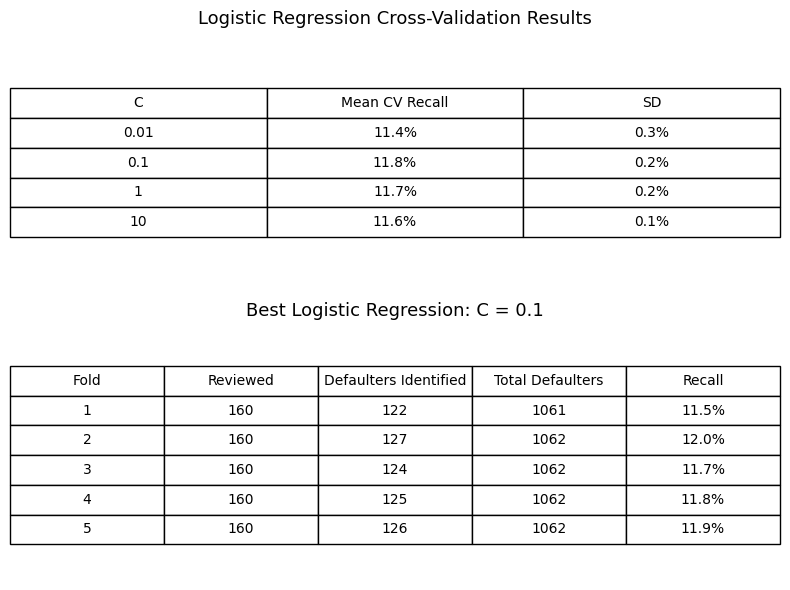

In [ ]:
# Logistic Regression Tables

import matplotlib.pyplot as plt
import pandas as pd

# Table 1: Logistic regression tuning
logistic_tuning = logistic_summary[
    ["C", "mean_recall", "sd_recall"]].copy()

logistic_tuning["C"] = logistic_tuning["C"].map(lambda x: f"{x:g}")
logistic_tuning["mean_recall"] = logistic_tuning["mean_recall"].map(lambda x: f"{x:.1%}")
logistic_tuning["sd_recall"] = logistic_tuning["sd_recall"].map(lambda x: f"{x:.1%}")

logistic_tuning = logistic_tuning.rename(columns={
    "C": "C",
    "mean_recall": "Mean CV Recall",
    "sd_recall": "SD",})

# Table 2: Best logistic regression across folds
best_logistic = logistic_results[
    logistic_results["C"] == best_C][["fold", "reviewed", "defaults_captured", "total_defaults", "recall"]].copy()

best_logistic["recall"] = best_logistic["recall"].map(lambda x: f"{x:.1%}")

best_logistic = best_logistic.rename(columns={
    "fold": "Fold",
    "reviewed": "Reviewed",
    "defaults_captured": "Defaulters Identified",
    "total_defaults": "Total Defaulters",
    "recall": "Recall",})


fig, axes = plt.subplots(2, 1, figsize=(8, 6))

# Tuning table
axes[0].axis("off")

table1 = axes[0].table(
    cellText=logistic_tuning.values,
    colLabels=logistic_tuning.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table1.auto_set_font_size(False)
table1.set_fontsize(10)
table1.scale(1, 1.5)

axes[0].set_title(
    "Logistic Regression Cross-Validation Results",
    fontsize=13,
    pad=10,)


# Best-model fold table
axes[1].axis("off")

table2 = axes[1].table(
    cellText=best_logistic.values,
    colLabels=best_logistic.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table2.auto_set_font_size(False)
table2.set_fontsize(10)
table2.scale(1, 1.5)

axes[1].set_title("Best Logistic Regression: C = 0.1",
    fontsize=13,pad=10,)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/logistic_regression_results.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [ ]:
# Random Forest

# Hyperparameters
max_depth_values = [4, 8, None]
min_leaf_values = [1, 10]

rf_results = []

for max_depth in max_depth_values:
    for min_leaf in min_leaf_values:
        for fold, (train_idx, val_idx) in enumerate(
            cv.split(X_train, y_train), start=1,):

            # Current CV split
            X_fold_train = X_train.iloc[train_idx]
            y_fold_train = y_train.iloc[train_idx]
            X_fold_val = X_train.iloc[val_idx]
            y_fold_val = y_train.iloc[val_idx]

            # Pipeline for this fold
            model = Pipeline([
                ("preprocess", ColumnTransformer([
                    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
                    ("num", "passthrough", numeric_cols),])),
                ("model", RandomForestClassifier(
                    n_estimators=300,
                    max_depth=max_depth,
                    min_samples_leaf=min_leaf,
                    max_features="sqrt",
                    random_state=SEED,
                    n_jobs=-1,)),])

            # Fit only on this fold's training data
            model.fit(X_fold_train, y_fold_train)

            # Default-risk probability on validation data
            val_risk = model.predict_proba(X_fold_val)[:, 1]

            # Evaluate the same bank decision
            result = evaluate_at_capacity(y_fold_val, val_risk)

            rf_results.append({
                "max_depth": max_depth,
                "min_samples_leaf": min_leaf,
                "fold": fold,
                "reviewed": result["reviewed"],
                "defaults_captured": result["defaults_captured"],
                "total_defaults": result["total_defaults"],
                "recall": result["recall"],})

rf_results = pd.DataFrame(rf_results)

assert (rf_results["reviewed"] == 160).all()

rf_summary = (
    rf_results
    .groupby(["max_depth", "min_samples_leaf"], dropna=False)
    .agg(
        mean_recall=("recall", "mean"),
        sd_recall=("recall", "std"),)
    .reset_index())

print(rf_summary.to_string(
    index=False,
    formatters={
        "mean_recall": "{:.3f}".format,
        "sd_recall": "{:.3f}".format,}))

best_rf_row = rf_summary.loc[
    rf_summary["mean_recall"].idxmax()]

best_depth = best_rf_row["max_depth"]
best_min_leaf = int(best_rf_row["min_samples_leaf"])

print("\nBest max_depth:", best_depth)
print("Best min_samples_leaf:", best_min_leaf)
print("Best RF CV Recall:", round(best_rf_row["mean_recall"], 3))

comparison = pd.DataFrame({
    "Model": ["Baseline", "Logistic Regression", "Random Forest"],
    "Mean CV Recall": [
        mean_baseline_recall,
        best_row["mean_recall"],
        best_rf_row["mean_recall"],],})

print(comparison.to_string(
    index=False,
    formatters={"Mean CV Recall": "{:.3f}".format},))

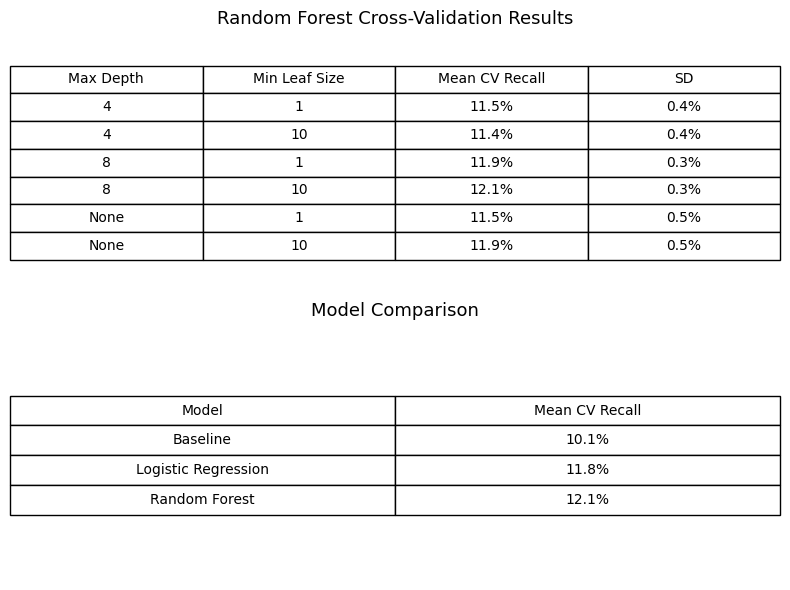

In [ ]:
# Random Forest Results Table

import matplotlib.pyplot as plt
import pandas as pd

# Tuning results

rf_table = rf_summary[
    ["max_depth", "min_samples_leaf", "mean_recall", "sd_recall"]
].copy()

# Replace NaN depth with "None"
rf_table["max_depth"] = rf_table["max_depth"].apply(
    lambda x: "None" if pd.isna(x) else str(int(x)))

# Format percentages
rf_table["mean_recall"] = rf_table["mean_recall"].map(lambda x: f"{x:.1%}")
rf_table["sd_recall"] = rf_table["sd_recall"].map(lambda x: f"{x:.1%}")

# Rename columns
rf_table = rf_table.rename(columns={
    "max_depth": "Max Depth",
    "min_samples_leaf": "Min Leaf Size",
    "mean_recall": "Mean CV Recall",
    "sd_recall": "SD",})

# Model Comparison
model_table = pd.DataFrame({
    "Model": ["Baseline", "Logistic Regression", "Random Forest"],
    "Mean CV Recall": [
        mean_baseline_recall,
        best_row["mean_recall"],
        best_rf_row["mean_recall"],],})

model_table["Mean CV Recall"] = (
    model_table["Mean CV Recall"].map(lambda x: f"{x:.1%}"))


fig, axes = plt.subplots(2, 1, figsize=(8, 6))

# Random forest tuning table
axes[0].axis("off")

table1 = axes[0].table(
    cellText=rf_table.values,
    colLabels=rf_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table1.auto_set_font_size(False)
table1.set_fontsize(10)
table1.scale(1, 1.4)

axes[0].set_title(
    "Random Forest Cross-Validation Results",
    fontsize=13,
    pad=10,)


# Model comparison table
axes[1].axis("off")

table2 = axes[1].table(
    cellText=model_table.values,
    colLabels=model_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table2.auto_set_font_size(False)
table2.set_fontsize(10)
table2.scale(1, 1.5)

axes[1].set_title(
    "Model Comparison",
    fontsize=13,
    pad=10,)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/random_forest_results.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()


# max_depth = None means there is no preset depth limit, so trees keep splitting until another stopping rule prevents further splits.
# The best random forest used max_depth=8 and min_samples_leaf=10, achieving a mean cross-validation recall of 12.1%.

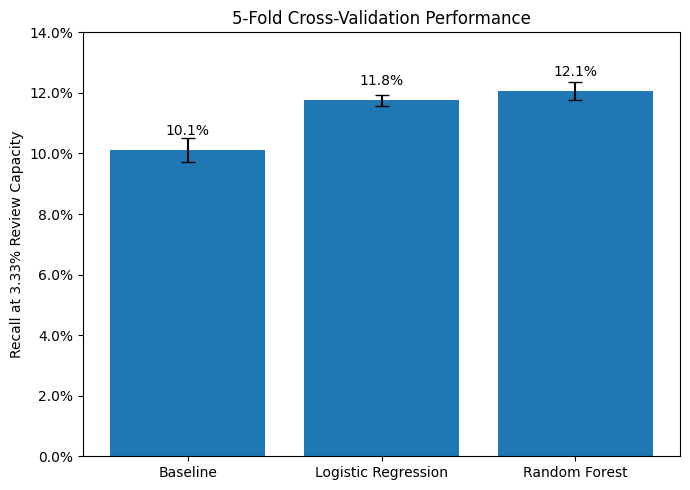

In [ ]:
# Bar Graph showing 5 CV Fold Performance

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


# Same-fold comparison
baseline_plot = baseline_results[
    ["fold", "recall"]
].rename(columns={"recall": "Baseline"})

logistic_plot = logistic_results[
    logistic_results["C"] == best_C
][["fold", "recall"]].rename(
    columns={"recall": "Logistic Regression"})

rf_plot = rf_results[
    (rf_results["max_depth"] == best_depth)
    & (rf_results["min_samples_leaf"] == best_min_leaf)
][["fold", "recall"]].rename(
    columns={"recall": "Random Forest"})

cv_comparison = (
    baseline_plot
    .merge(logistic_plot, on="fold")
    .merge(rf_plot, on="fold"))

model_names = ["Baseline", "Logistic Regression", "Random Forest"]

means = cv_comparison[model_names].mean()
stds = cv_comparison[model_names].std()


# Create bar graph
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    model_names,
    means,
    yerr=stds,
    capsize=5,)

ax.set_ylabel("Recall at 3.33% Review Capacity")
ax.set_title("5-Fold Cross-Validation Performance")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 0.14)

for bar, mean in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.004,
        f"{mean:.1%}",
        ha="center",
        va="bottom",)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/cv_model_comparison.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()


# Figure 1. Mean 5-fold cross-validation recall for the baseline, logistic regression, and random forest.
# All methods use the same validation folds and 160-account review capacity; error bars show one standard deviation across folds.

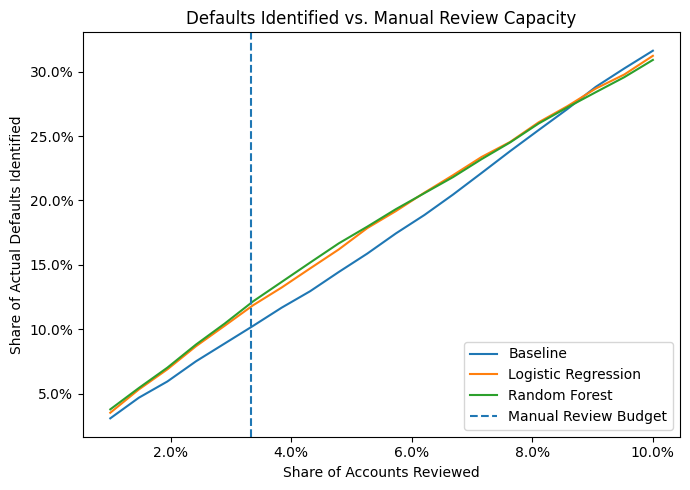

In [ ]:
# Line Graph Showing Model Performance
# Capacity Curve: Baseline vs Logistic vs Random Forest

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Review capacities from 1% to 10%
review_rates = np.linspace(0.01, 0.10, 20)

baseline_curves = []
logistic_curves = []
rf_curves = []

for train_idx, val_idx in cv.split(X_train, y_train):

    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Logistic regression
    logistic = Pipeline([
        ("preprocess", logistic_preprocessor),
        ("model", LogisticRegression(
            C=best_C,
            penalty="l2",
            max_iter=5000,
            random_state=SEED,)),])

    logistic.fit(X_fold_train, y_fold_train)
    logistic_risk = logistic.predict_proba(X_fold_val)[:, 1]

    # Random forest
    rf = Pipeline([
        ("preprocess", tree_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=int(best_depth),
            min_samples_leaf=best_min_leaf,
            max_features="sqrt",
            random_state=SEED,
            n_jobs=-1,)),])

    rf.fit(X_fold_train, y_fold_train)
    rf_risk = rf.predict_proba(X_fold_val)[:, 1]

    # Recall curves for this validation fold
    baseline_fold = []
    logistic_fold = []
    rf_fold = []

    for rate in review_rates:
        baseline_result = evaluate_baseline(
            X_fold_val,
            y_fold_val,
            review_rate=rate,)

        baseline_fold.append(baseline_result["recall"])

        logistic_fold.append(
            recall_at_capacity(
                y_fold_val,
                logistic_risk,
                review_rate=rate,))

        rf_fold.append(
            recall_at_capacity(
                y_fold_val,
                rf_risk,
                review_rate=rate,))

    baseline_curves.append(baseline_fold)
    logistic_curves.append(logistic_fold)
    rf_curves.append(rf_fold)


# Average across the 5 CV folds
baseline_curve = np.mean(baseline_curves, axis=0)
logistic_curve = np.mean(logistic_curves, axis=0)
rf_curve = np.mean(rf_curves, axis=0)


# Plot
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(review_rates, baseline_curve, label="Baseline")
ax.plot(review_rates, logistic_curve, label="Logistic Regression")
ax.plot(review_rates, rf_curve, label="Random Forest")

# Bank's actual 3.33% review capacity
ax.axvline(
    REVIEW_RATE,
    linestyle="--",
    label="Manual Review Budget",)

ax.set_xlabel("Share of Accounts Reviewed")
ax.set_ylabel("Share of Actual Defaults Identified")
ax.set_title("Defaults Identified vs. Manual Review Capacity")

ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.legend()

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/cv_capacity_curve.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()

In [ ]:
# Random Forest + K-Means

from sklearn.cluster import KMeans

# Variables used to define customer behavior
behavior_cat_cols = [
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",]

behavior_num_cols = [
    "LIMIT_BAL",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",]

K_values = [3, 4, 5]
cluster_results = []

for k in K_values:
    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train), start=1,):

        # Current CV split
        X_tr = X_train.iloc[train_idx].copy()
        y_tr = y_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx].copy()
        y_val = y_train.iloc[val_idx]

        # Prepare behavioral variables for K-means
        behavior_preprocessor = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), behavior_cat_cols),
            ("num", StandardScaler(), behavior_num_cols),])

        Z_tr = behavior_preprocessor.fit_transform(X_tr)
        Z_val = behavior_preprocessor.transform(X_val)

        # Fit K-means on training fold only
        kmeans = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=SEED,)

        kmeans.fit(Z_tr)

        # Distance from each customer to each cluster center
        dist_tr = kmeans.transform(Z_tr)
        dist_val = kmeans.transform(Z_val)

        # Add cluster distances as new model features
        distance_cols = [f"cluster_dist_{j}" for j in range(k)]

        for j, col in enumerate(distance_cols):
            X_tr[col] = dist_tr[:, j]
            X_val[col] = dist_val[:, j]

        # Random Forest with K-means features
        preprocessor = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ("num", "passthrough", numeric_cols + distance_cols),])

        model = Pipeline([
            ("preprocess", preprocessor),
            ("model", RandomForestClassifier(
                n_estimators=300,
                max_depth=int(best_depth),
                min_samples_leaf=best_min_leaf,
                max_features="sqrt",
                random_state=SEED,
                n_jobs=-1,)),])

        model.fit(X_tr, y_tr)
        val_risk = model.predict_proba(X_val)[:, 1]

        # Same Recall@3.33% decision metric
        result = evaluate_at_capacity(y_val, val_risk)

        cluster_results.append({
            "k": k,
            "fold": fold,
            "reviewed": result["reviewed"],
            "recall": result["recall"],})

# Summarize Results

cluster_results = pd.DataFrame(cluster_results)

cluster_summary = (
    cluster_results
    .groupby("k")
    .agg(mean_recall=("recall", "mean"),
        sd_recall=("recall", "std"),)
    .reset_index())

print(cluster_summary.to_string(
    index=False,
    formatters={
        "mean_recall": "{:.3f}".format,
        "sd_recall": "{:.3f}".format,}))

# Best K-Means Model

best_cluster_row = cluster_summary.loc[
    cluster_summary["mean_recall"].idxmax()]

best_k = int(best_cluster_row["k"])

print("\nBest k:", best_k)
print("Original RF CV Recall:", round(best_rf_row["mean_recall"], 3))
print("RF + K-Means CV Recall:", round(best_cluster_row["mean_recall"], 3))

print("Improvement:",round(best_cluster_row["mean_recall"] - best_rf_row["mean_recall"],3,))

 k mean_recall sd_recall
 3       0.119     0.004
 4       0.119     0.002
 5       0.118     0.003

Best k: 4
Original RF CV Recall: 0.121
RF + K-Means CV Recall: 0.119
Improvement: -0.001


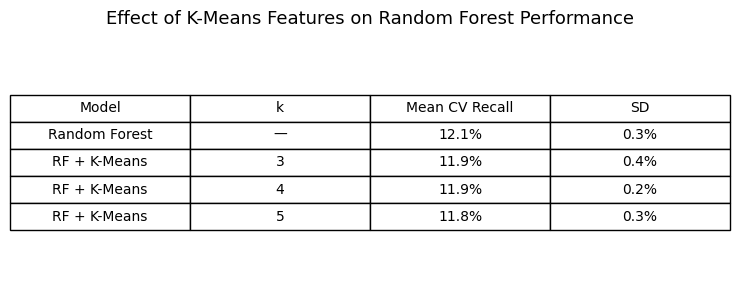

In [ ]:
# Random Forest + K-Means Results Table

import matplotlib.pyplot as plt
import pandas as pd


# Original random forest benchmark
rf_row = pd.DataFrame({
    "Model": ["Random Forest"],
    "k": ["—"],
    "Mean CV Recall": [best_rf_row["mean_recall"]],
    "SD": [best_rf_row["sd_recall"]],})

# K-means results
kmeans_table = cluster_summary[
    ["k", "mean_recall", "sd_recall"]].copy()

kmeans_table["Model"] = "RF + K-Means"

kmeans_table = kmeans_table.rename(columns={
    "mean_recall": "Mean CV Recall",
    "sd_recall": "SD",})

kmeans_table = kmeans_table[
    ["Model", "k", "Mean CV Recall", "SD"]]

# Combine benchmark and K-means results
results_table = pd.concat(
    [rf_row, kmeans_table],
    ignore_index=True,)

# Format percentages
results_table["Mean CV Recall"] = (
    results_table["Mean CV Recall"]
    .map(lambda x: f"{x:.1%}"))

results_table["SD"] = (
    results_table["SD"]
    .map(lambda x: f"{x:.1%}"))

fig, ax = plt.subplots(figsize=(7.5, 3))

ax.axis("off")

table = ax.table(
    cellText=results_table.values,
    colLabels=results_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

ax.set_title(
    "Effect of K-Means Features on Random Forest Performance",
    fontsize=13,
    pad=15,)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/kmeans_results_table.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()

In [ ]:
# Logistic Regression + K-Means

from sklearn.cluster import KMeans


# Behavioral variables for K-means
behavior_cat_cols = [
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",]

behavior_num_cols = [
    "LIMIT_BAL",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",]

K_values = [3, 4, 5]
logistic_cluster_results = []

for k in K_values:
    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train), start=1,):

        # Current CV split
        X_tr = X_train.iloc[train_idx].copy()
        y_tr = y_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx].copy()
        y_val = y_train.iloc[val_idx]

        # Prepare behavioral variables for K-means
        behavior_preprocessor = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), behavior_cat_cols),
            ("num", StandardScaler(), behavior_num_cols),])

        Z_tr = behavior_preprocessor.fit_transform(X_tr)
        Z_val = behavior_preprocessor.transform(X_val)

        # Fit K-means on training fold only
        kmeans = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=SEED,)

        kmeans.fit(Z_tr)

        dist_tr = kmeans.transform(Z_tr)
        dist_val = kmeans.transform(Z_val)

        # Add cluster distances as new features
        distance_cols = [f"cluster_dist_{j}" for j in range(k)]

        for j, col in enumerate(distance_cols):
            X_tr[col] = dist_tr[:, j]
            X_val[col] = dist_val[:, j]

        # Logistic regression with K-means features
        preprocessor = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ("num", StandardScaler(), numeric_cols + distance_cols),])

        model = Pipeline([
            ("preprocess", preprocessor),
            ("model", LogisticRegression(
                C=best_C,
                penalty="l2",
                max_iter=5000,
                random_state=SEED,)),])

        model.fit(X_tr, y_tr)
        val_risk = model.predict_proba(X_val)[:, 1]

        result = evaluate_at_capacity(y_val, val_risk)

        logistic_cluster_results.append({
            "k": k,
            "fold": fold,
            "recall": result["recall"],})

# Summarize Results

logistic_cluster_results = pd.DataFrame(logistic_cluster_results)

logistic_cluster_summary = (
    logistic_cluster_results
    .groupby("k")
    .agg(
        mean_recall=("recall", "mean"),
        sd_recall=("recall", "std"),)
    .reset_index())

print(logistic_cluster_summary.to_string(
    index=False,
    formatters={
        "mean_recall": "{:.3f}".format,
        "sd_recall": "{:.3f}".format,}))

# Compare with Original Logistic Regression

best_logistic_cluster = logistic_cluster_summary.loc[
    logistic_cluster_summary["mean_recall"].idxmax()]

best_logistic_k = int(best_logistic_cluster["k"])

print("\nBest k:", best_logistic_k)
print("Original Logistic CV Recall:", round(best_row["mean_recall"], 3))

print(
    "Logistic + K-Means CV Recall:",
    round(best_logistic_cluster["mean_recall"], 3),)

print(
    "Improvement:",
    round(
        best_logistic_cluster["mean_recall"] - best_row["mean_recall"],
        3,))

 k mean_recall sd_recall
 3       0.117     0.002
 4       0.116     0.001
 5       0.116     0.001

Best k: 3
Original Logistic CV Recall: 0.118
Logistic + K-Means CV Recall: 0.117
Improvement: -0.001


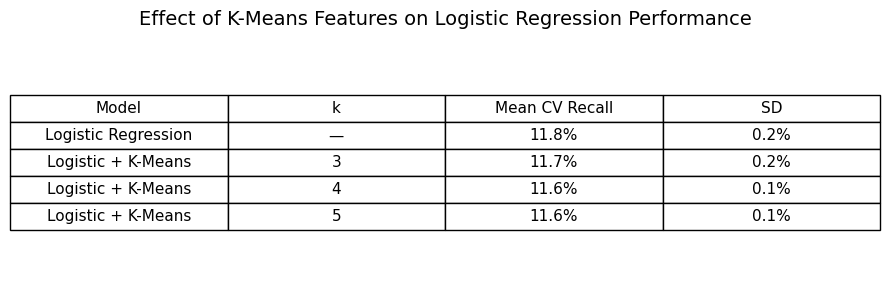

In [ ]:
# Logistic Regression + K-Means Results Table

import matplotlib.pyplot as plt
import pandas as pd


# Original logistic regression result
original_logistic_recall = best_row["mean_recall"]
original_logistic_sd = best_row["sd_recall"]


# Build table data
table_data = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic + K-Means",
        "Logistic + K-Means",
        "Logistic + K-Means",],
    "k": ["—", 3, 4, 5],
    "Mean CV Recall": [
        original_logistic_recall,
        logistic_cluster_summary.loc[
            logistic_cluster_summary["k"] == 3,
            "mean_recall"].iloc[0],
        logistic_cluster_summary.loc[
            logistic_cluster_summary["k"] == 4,
            "mean_recall"].iloc[0],
        logistic_cluster_summary.loc[
            logistic_cluster_summary["k"] == 5,
            "mean_recall"].iloc[0],],
    "SD": [
        original_logistic_sd,
        logistic_cluster_summary.loc[
            logistic_cluster_summary["k"] == 3,
            "sd_recall"].iloc[0],
        logistic_cluster_summary.loc[
            logistic_cluster_summary["k"] == 4,
            "sd_recall"].iloc[0],
        logistic_cluster_summary.loc[
            logistic_cluster_summary["k"] == 5,
            "sd_recall"].iloc[0],],})


# Convert recall and SD to percentages
table_data["Mean CV Recall"] = (
    table_data["Mean CV Recall"] * 100
).map("{:.1f}%".format)

table_data["SD"] = (
    table_data["SD"] * 100
).map("{:.1f}%".format)

fig, ax = plt.subplots(figsize=(9, 3))

ax.axis("off")

table = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellLoc="center",
    loc="center",)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)

ax.set_title(
    "Effect of K-Means Features on Logistic Regression Performance",
    fontsize=14,
    pad=15,)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/logistic_kmeans_results_table.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()

Training customers: 24000
Test customers: 6000
Final review capacity: 200

FINAL HELD-OUT TEST PERFORMANCE
              Model  Reviewed  Defaulters Identified  Total Defaulters Test Recall
           Baseline       200                    138              1327       10.4%
Logistic Regression       200                    157              1327       11.8%
      Random Forest       200                    155              1327       11.7%

Sanity checks passed.


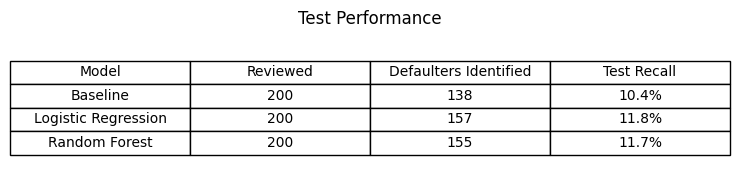

In [ ]:
# Held-Out Test Performance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

TEST_CAPACITY = 200

assert len(X_train) == 24000
assert len(X_test) == 6000
assert TEST_CAPACITY == 200

print("Training customers:", len(X_train))
print("Test customers:", len(X_test))
print("Final review capacity:", TEST_CAPACITY)


# Evaluate Exactly Top 200

def evaluate_top_200(y_true, risk_scores):
    results = pd.DataFrame({
        "actual_default": np.asarray(y_true),
        "risk_score": np.asarray(risk_scores),})

    results = results.sort_values("risk_score", ascending=False)
    reviewed = results.head(TEST_CAPACITY)

    total_defaults = int(results["actual_default"].sum())
    defaults_identified = int(reviewed["actual_default"].sum())
    recall = defaults_identified / total_defaults

    return {
        "reviewed": TEST_CAPACITY,
        "defaults_identified": defaults_identified,
        "total_defaults": total_defaults,
        "recall": recall,}

# Baseline

baseline_test = X_test.copy()
baseline_test["actual_default"] = y_test.values

# Most recent bill balance relative to credit limit
baseline_test["utilization"] = (
    baseline_test["BILL_AMT1"] / baseline_test["LIMIT_BAL"])

# Locked baseline:
# 1. Rank by most recent repayment delay
# 2. Break ties using utilization
baseline_ranked = baseline_test.sort_values(
    by=["PAY_0", "utilization"],
    ascending=[False, False],)

baseline_reviewed = baseline_ranked.head(TEST_CAPACITY)

baseline_defaults_identified = int(
    baseline_reviewed["actual_default"].sum())

test_total_defaults = int(
    baseline_test["actual_default"].sum())

baseline_test_recall = (
    baseline_defaults_identified / test_total_defaults)


# Logistic Regression

logistic_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols),])

final_logistic = Pipeline([
    ("preprocess", logistic_preprocessor),
    ("model", LogisticRegression(
        C=best_C,
        penalty="l2",
        max_iter=5000,
        random_state=SEED,)),])

# Fit on all 24,000 training customers
final_logistic.fit(X_train, y_train)

# Predict risk on held-out test set
logistic_test_risk = final_logistic.predict_proba(X_test)[:, 1]

logistic_test_result = evaluate_top_200(
    y_test,
    logistic_test_risk,)


# Random Forest

tree_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", "passthrough", numeric_cols),])

final_rf = Pipeline([
    ("preprocess", tree_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=-1,)),])

# Fit on all 24,000 training customers
final_rf.fit(X_train, y_train)

# Predict risk on the same held-out test set
rf_test_risk = final_rf.predict_proba(X_test)[:, 1]

rf_test_result = evaluate_top_200(
    y_test,
    rf_test_risk,)


# Results

final_test_results = pd.DataFrame({
    "Model": ["Baseline", "Logistic Regression", "Random Forest"],
    "Reviewed": [
        TEST_CAPACITY,
        logistic_test_result["reviewed"],
        rf_test_result["reviewed"],],
    "Defaulters Identified": [
        baseline_defaults_identified,
        logistic_test_result["defaults_identified"],
        rf_test_result["defaults_identified"],],
    "Total Defaulters": [
        test_total_defaults,
        logistic_test_result["total_defaults"],
        rf_test_result["total_defaults"],],
    "Test Recall": [
        baseline_test_recall,
        logistic_test_result["recall"],
        rf_test_result["recall"],],})

display_table = final_test_results.copy()

display_table["Test Recall"] = (
    display_table["Test Recall"] * 100
).map("{:.1f}%".format)

print("\nFINAL HELD-OUT TEST PERFORMANCE")
print(display_table.to_string(index=False))


# Sanity Checks

assert logistic_test_result["total_defaults"] == test_total_defaults
assert rf_test_result["total_defaults"] == test_total_defaults
assert logistic_test_result["reviewed"] == TEST_CAPACITY
assert rf_test_result["reviewed"] == TEST_CAPACITY

print("\nSanity checks passed.")


report_test_table = final_test_results[
    ["Model", "Reviewed", "Defaulters Identified", "Test Recall"]
].copy()

report_test_table["Test Recall"] = (
    report_test_table["Test Recall"] * 100
).map("{:.1f}%".format)


fig, ax = plt.subplots(figsize=(7.5, 2.0))

ax.axis("off")

table = ax.table(
    cellText=report_test_table.values,
    colLabels=report_test_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)

# Nothing bold
for cell in table.get_celld().values():
    cell.set_text_props(weight="normal")

ax.set_title(
    "Test Performance",
    fontsize=12,
    fontweight="normal",
    pad=8,)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/final_test_results_table.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()

In [ ]:
# Failure Analysis

# Setting up Logistic Regression since it was the best test performance model.

final_logistic = Pipeline([
    ("preprocess", logistic_preprocessor),
    ("model", LogisticRegression(
        C=best_C,
        penalty="l2",
        max_iter=5000,
        random_state=SEED,)),])

final_logistic.fit(X_train, y_train)
test_risk = final_logistic.predict_proba(X_test)[:, 1]


# Decision to choose top 200 accounts for review

selected = np.zeros(len(X_test), dtype=bool)

top_200 = np.argsort(test_risk)[::-1][:200]
selected[top_200] = True


# Build test-set table

test_df = X_test.copy()

test_df["default"] = np.asarray(y_test)
test_df["selected"] = selected
test_df["predicted_risk"] = test_risk

# Age groups
test_df["age_group"] = pd.cut(
    test_df["AGE"],
    bins=[0, 29, 39, 49, np.inf],
    labels=["<30", "30-39", "40-49", "50+"],)

# Credit-limit groups based on training data
q1, q2, q3 = X_train["LIMIT_BAL"].quantile(
    [0.25, 0.50, 0.75])

test_df["limit_group"] = pd.cut(
    test_df["LIMIT_BAL"],
    bins=[-np.inf, q1, q2, q3, np.inf],
    labels=["Q1", "Q2", "Q3", "Q4"],)

# 95% Confidence interval

def confidence_interval(captured, defaults):
    if defaults == 0:
        return np.nan, np.nan

    p = captured / defaults
    z = 1.96

    center = (
        p + z**2 / (2 * defaults)
    ) / (
        1 + z**2 / defaults)

    width = (
        z * np.sqrt(
            p * (1 - p) / defaults
            + z**2 / (4 * defaults**2))
        / (1 + z**2 / defaults))

    return center - width, center + width

# Slice summary

def summarize_slices(df, column):
    results = []

    for group, data in df.groupby(column, observed=True):
        n = len(data)
        defaults = int(data["default"].sum())
        captured = int((data["default"] * data["selected"]).sum())
        recall = captured / defaults if defaults > 0 else np.nan

        lower, upper = confidence_interval(captured, defaults)

        results.append({
            "slice": str(group),
            "n": n,
            "defaults": defaults,
            "captured": captured,
            "recall": recall,
            "lower_95": lower,
            "upper_95": upper,})

    return pd.DataFrame(results)


# Age and credit-limit results

age_results = summarize_slices(test_df, "age_group")
age_results["variable"] = "Age"

limit_results = summarize_slices(test_df, "limit_group")
limit_results["variable"] = "Credit Limit"

slice_results = pd.concat(
    [age_results, limit_results],
    ignore_index=True,)

print(slice_results[
    [   "variable",
        "slice",
        "n",
        "defaults",
        "captured",
        "recall",
        "lower_95",
        "upper_95",]].round(3))


# Worst slice

worst_slice = slice_results.loc[
    slice_results["recall"].idxmin()]

print("\nWorst slice:")

print(worst_slice[
    [   "variable",
        "slice",
        "n",
        "defaults",
        "captured",
        "recall",
        "lower_95",
        "upper_95",]])

       variable  slice     n  defaults  captured  recall  lower_95  upper_95
0           Age    <30  1891       418        52   0.124     0.096     0.160
1           Age  30-39  2248       488        50   0.102     0.079     0.133
2           Age  40-49  1333       295        43   0.146     0.110     0.191
3           Age    50+   528       126        12   0.095     0.055     0.159
4  Credit Limit     Q1  1523       490        74   0.151     0.122     0.185
5  Credit Limit     Q2  1501       364        50   0.137     0.106     0.177
6  Credit Limit     Q3  1539       274        26   0.095     0.066     0.135
7  Credit Limit     Q4  1437       199         7   0.035     0.017     0.071

Worst slice:
variable    Credit Limit
slice                 Q4
n                   1437
defaults             199
captured               7
recall          0.035176
lower_95        0.017142
upper_95        0.070817
Name: 7, dtype: object


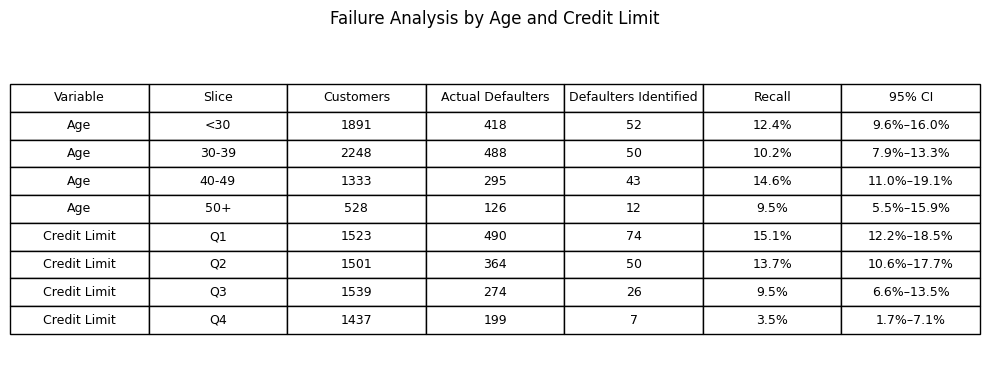

In [ ]:
# Failure Analysis Results Table

import matplotlib.pyplot as plt
import pandas as pd


# Keep columns needed for report
failure_table = slice_results[
    [   "variable",
        "slice",
        "n",
        "defaults",
        "captured",
        "recall",
        "lower_95",
        "upper_95",]].copy()

# Combine confidence interval into one column
failure_table["95% CI"] = failure_table.apply(
    lambda row: f"{row['lower_95']:.1%}–{row['upper_95']:.1%}",
    axis=1,)

# Format recall
failure_table["recall"] = failure_table["recall"].map(
    lambda x: f"{x:.1%}")

# Rename columns
failure_table = failure_table.rename(columns={
    "variable": "Variable",
    "slice": "Slice",
    "n": "Customers",
    "defaults": "Actual Defaulters",
    "captured": "Defaulters Identified",
    "recall": "Recall",})

# Keep final report columns
failure_table = failure_table[
    [   "Variable",
        "Slice",
        "Customers",
        "Actual Defaulters",
        "Defaulters Identified",
        "Recall",
        "95% CI",]]


fig, ax = plt.subplots(figsize=(10, 4))

ax.axis("off")

table = ax.table(
    cellText=failure_table.values,
    colLabels=failure_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)

ax.set_title(
    "Failure Analysis by Age and Credit Limit",
    fontsize=12,
    pad=10,)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/failure_analysis_table.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()

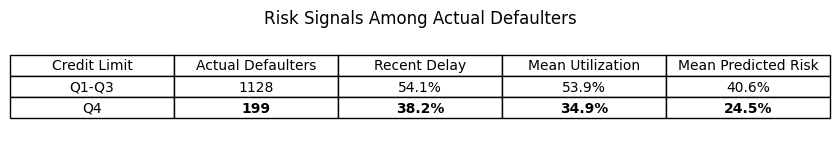

In [ ]:
# Worst Credit-Limit Slice Table

import matplotlib.pyplot as plt

# Actual defaulters only
defaulted = test_df[test_df["default"] == 1].copy()

# Compare Q4 against the lower three credit-limit groups
defaulted["group"] = np.where(
    defaulted["limit_group"] == "Q4",
    "Q4",
    "Q1-Q3",)

# Recent repayment delay indicator
defaulted["recent_delay"] = (
    defaulted["PAY_0"] >= 1
).astype(int)

# Most recent bill balance relative to credit limit
defaulted["utilization"] = (
    defaulted["BILL_AMT1"] / defaulted["LIMIT_BAL"])

# Diagnostic comparison
comparison = defaulted.groupby("group").agg(
    actual_defaulters=("default", "size"),
    pct_recent_delay=("recent_delay", "mean"),
    mean_utilization=("utilization", "mean"),
    mean_predicted_risk=("predicted_risk", "mean"),)

comparison["pct_recent_delay"] *= 100


report_table = comparison.loc[
    ["Q1-Q3", "Q4"],
    [   "actual_defaulters",
        "pct_recent_delay",
        "mean_utilization",
        "mean_predicted_risk",]].copy()

report_table.columns = [
    "Actual Defaulters",
    "Recent Delay",
    "Mean Utilization",
    "Mean Predicted Risk",]

report_table.insert(
    0,
    "Credit Limit",
    ["Q1-Q3", "Q4"],)

# Format values
report_table["Recent Delay"] = (
    report_table["Recent Delay"]
    .map("{:.1f}%".format))

report_table["Mean Utilization"] = (
    report_table["Mean Utilization"] * 100
).map("{:.1f}%".format)

report_table["Mean Predicted Risk"] = (
    report_table["Mean Predicted Risk"] * 100
).map("{:.1f}%".format)

fig, ax = plt.subplots(figsize=(8.5, 1.6))

ax.axis("off")

table = ax.table(
    cellText=report_table.values,
    colLabels=report_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)

# Bold only Q4 diagnostic values
for col in range(1, len(report_table.columns)):
    table[(2, col)].set_text_props(weight="bold")

ax.set_title(
    "Risk Signals Among Actual Defaulters",
    fontsize=12,
    pad=8,)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/q4_failure_diagnostic.png",
    dpi=300,
    bbox_inches="tight",)

plt.show()